# FIRETEC results

This notebook visualizes a FIRETEC 1.5.0 run that `firetec_to_zarr.py` converted
to Zarr: where and when the fire burned, how much fuel it consumed, and the heat,
fire-driven winds and plume above it.

**Before you start**

- Choose the **Python (FIRETEC)** kernel. `TOOLS/NDP/install.sh` registers it;
  run that script again after the NDP server restarts.
- Convert the run first: `python3 TOOLS/Postprocessing/firetec_to_zarr.py <case folder>`.
- Point `STORE` below at the `.zarr` folder (or set the `FIRETEC_ZARR`
  environment variable), then run all cells.

## Settings

In [1]:
import os
from pathlib import Path

# The store firetec_to_zarr.py wrote; the FIRETEC_ZARR environment variable overrides it.
STORE = Path(os.environ.get("FIRETEC_ZARR", "../TestRun-64x32-N8/TestRun-64x32-N8.zarr"))
# STORE = Path('../TestRun-256x256-CPU-N16/TestRun-256x256-CPU-N16.zarr')
# "light" or "dark", to match your JupyterLab theme (FIRETEC_PLOT_THEME overrides it).
THEME = os.environ.get("FIRETEC_PLOT_THEME", "light")

# A ground cell counts as burned once this fraction of its fuel is gone.
BURNED_FRACTION = 0.10

# Air at least this much warmer than ambient (K, above 0) counts as part of the
# plume; it is also the bottom of the fire animation's logarithmic color scale.
PLUME_THETA_RISE = 1.0

# How many near-ground maps to draw across the time the fire is active.
SNAPSHOT_COUNT = 4

# Draw the model's cell edges on maps; on finer grids only every n-th edge, so
# that at most MAX_GRID_LINES lines run in each direction. Plots with a height axis
# leave them out: the stretched vertical cells crowd together near the ground.
SHOW_CELL_GRID = True
MAX_GRID_LINES = 100

# The fire animation shows at most this many outputs, spread over the run.
MAX_ANIMATION_FRAMES = 60

# A folder to also save every figure to as PNG, or None (FIRETEC_FIGURES overrides it).
SAVE_FIGURES_TO = os.environ.get("FIRETEC_FIGURES")

## Style

Colors follow a validated palette with separate light and dark steps: a one-hue
blue ramp for amounts (its lightest step means "none"), a shorter blue ramp for
times (every step stays visible), a neutral-yellow-red ramp for heating, blue for
wind arrows and lines, and orange for ignition. Hairlines in the grid color mark the
model's cell edges on maps.

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import HTML, Markdown, display
from matplotlib.animation import FuncAnimation
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D

PALETTES = {
    "light": {
        "surface": "#fcfcfb", "ink": "#0b0b0b", "ink_secondary": "#52514e",
        "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7",
        "series": "#2a78d6", "ignition": "#eb6834",
        "amount": ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"],
        "order": ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"],
        "heat": ["#f0efec", "#eda100", "#e34948"],
    },
    "dark": {
        "surface": "#1a1a19", "ink": "#f0efec", "ink_secondary": "#c3c2b7",
        "muted": "#898781", "grid": "#2c2c2a", "axis": "#383835",
        "series": "#3987e5", "ignition": "#d95926",
        "amount": ["#0d366b", "#184f95", "#256abf", "#3987e5", "#6da7ec", "#9ec5f4", "#cde2fb"],
        "order": ["#184f95", "#256abf", "#3987e5", "#6da7ec", "#9ec5f4", "#cde2fb"],
        "heat": ["#383835", "#e34948", "#eda100"],
    },
}
if THEME not in PALETTES:
    raise ValueError(f"THEME must be one of {sorted(PALETTES)}, not {THEME!r}")
COLORS = PALETTES[THEME]
AMOUNT_CMAP = LinearSegmentedColormap.from_list("amount", COLORS["amount"])
ORDER_CMAP = LinearSegmentedColormap.from_list("order", COLORS["order"])
HEAT_CMAP = LinearSegmentedColormap.from_list("heat", COLORS["heat"])
for colormap in (AMOUNT_CMAP, ORDER_CMAP, HEAT_CMAP):
    colormap.set_bad(alpha=0)   # cells without a value show the background

mpl.rcParams.update({
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "savefig.facecolor": COLORS["surface"], "figure.dpi": 110, "savefig.dpi": 200,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": COLORS["ink"], "axes.titlecolor": COLORS["ink"],
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.titlesize": 13, "figure.titleweight": "bold",
    "axes.labelcolor": COLORS["ink_secondary"], "axes.edgecolor": COLORS["axis"],
    "axes.linewidth": 0.8,
    "xtick.color": COLORS["axis"], "ytick.color": COLORS["axis"],
    "xtick.labelcolor": COLORS["ink_secondary"], "ytick.labelcolor": COLORS["ink_secondary"],
    "grid.color": COLORS["grid"], "grid.linewidth": 0.8, "grid.linestyle": "-",
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "legend.labelcolor": COLORS["ink_secondary"],
})


def finish(fig, name):
    """Show a figure and, if SAVE_FIGURES_TO is set, save it there as PNG."""
    if SAVE_FIGURES_TO:
        folder = Path(SAVE_FIGURES_TO)
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / f"{name}.png", bbox_inches="tight")
    plt.show()


def add_colorbar(fig, mappable, ax, label, **kwargs):
    bar = fig.colorbar(mappable, ax=ax, shrink=0.9, pad=0.02, aspect=30, **kwargs)
    bar.set_label(label)
    bar.outline.set_visible(False)
    return bar


def style_map(ax, title):
    """Equal-scale x-y map in metres with a hairline frame."""
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(title)


def cell_edges(centres):
    """Cell edges from evenly spaced cell centres."""
    step = centres[1] - centres[0] if centres.size > 1 else 1.0
    return np.append(centres - step / 2, centres[-1] + step / 2)


def outline_segments(mask, x_edges, y_edges):
    """Line segments along the cell edges between masked and unmasked cells."""
    padded = np.pad(mask, 1)
    between_columns = padded[1:-1, 1:] != padded[1:-1, :-1]    # (y, x + 1)
    between_rows = padded[1:, 1:-1] != padded[:-1, 1:-1]       # (y + 1, x)
    vertical = [[(x_edges[i], y_edges[j]), (x_edges[i], y_edges[j + 1])]
                for j, i in zip(*np.nonzero(between_columns))]
    horizontal = [[(x_edges[i], y_edges[j]), (x_edges[i + 1], y_edges[j])]
                  for j, i in zip(*np.nonzero(between_rows))]
    return vertical + horizontal


def grid_step(count):
    """Draw every n-th cell edge so that at most MAX_GRID_LINES are drawn."""
    return max(1, int(np.ceil(count / MAX_GRID_LINES)))


def add_map_grid(ax, ds):
    """Hairlines along the model's horizontal (x-y) cell edges."""
    if not SHOW_CELL_GRID:
        return
    x_edges, y_edges = cell_edges(ds.x.values), cell_edges(ds.y.values)
    style = {"colors": COLORS["grid"], "linewidths": 0.5, "zorder": 2}
    ax.vlines(x_edges[::grid_step(x_edges.size)], y_edges[0], y_edges[-1], **style)
    ax.hlines(y_edges[::grid_step(y_edges.size)], x_edges[0], x_edges[-1], **style)


def section_corners(ds, row):
    """Cell corners of the vertical slice along one y row: x and height above
    ground, each (z edges, x edges). The vertical cells are stretched, and
    terrain-following runs squeeze them over high ground."""
    x_edges = cell_edges(ds.x.values)
    z_edges = np.append(ds.z_bounds.values[:, 0], ds.z_bounds.values[-1, 1])
    ground = np.zeros(x_edges.size)
    if "terrain_height" in ds:
        ground = np.interp(x_edges, ds.x.values, ds.terrain_height.isel(y=row).values)
    top = ds.z.attrs["domain_top"]
    heights = z_edges[:, None] * (top - ground) / top
    return np.broadcast_to(x_edges, heights.shape), heights


def add_ignition_outline(ax, ds):
    """Outline the ignited cells in orange; returns a legend handle (or None)."""
    if "ignition_i" not in ds:
        return None
    ignited = np.zeros((ds.sizes["y"], ds.sizes["x"]), dtype=bool)
    ignited[ds.ignition_j.values - 1, ds.ignition_i.values - 1] = True
    segments = outline_segments(ignited, cell_edges(ds.x.values), cell_edges(ds.y.values))
    ax.add_collection(LineCollection(segments, colors=COLORS["ignition"], linewidths=1.5,
                                     capstyle="round", zorder=3))
    return Line2D([], [], color=COLORS["ignition"], linewidth=1.5, label="Ignited cells")


def round_down(value):
    """The largest 1, 2 or 5 x 10^k not above value (for arrow keys)."""
    if not np.isfinite(value) or value <= 0:
        return 1.0
    magnitude = 10 ** np.floor(np.log10(value))
    return float(max(m * magnitude for m in (1, 2, 5) if m * magnitude <= value))


def wind_arrows(ax, x, y, u, v, longest, max_speed, units="xy"):
    """Wind arrows scaled so the fastest is `longest` long: in data units on
    equal-scale maps, or in inches (with true screen angles) on stretched axes.
    Arrows too short to see are left out rather than drawn as dots."""
    return ax.quiver(x, y, u, v, color=COLORS["series"],
                     angles="xy" if units == "xy" else "uv", scale_units=units,
                     scale=max(max_speed, 1e-9) / longest, width=0.003, minlength=0,
                     headwidth=4, headlength=4.5, headaxislength=4, zorder=3)


def streamline_width(speed, fastest):
    """Streamline width in points: thin in calm air, 2 pt at the fastest wind."""
    return 0.4 + 1.6 * speed / max(fastest, 1e-9)


def wind_streamlines(ax, ds, u, v, fastest):
    """Horizontal wind as streamlines whose width grows with speed."""
    ax.streamplot(ds.x.values, ds.y.values, u, v, density=1.2, color=COLORS["series"],
                  linewidth=streamline_width(np.hypot(u, v), fastest), arrowsize=0.8,
                  zorder=3)


def streamline_legend(fig, fastest):
    """Legend keys for the streamline widths."""
    handles = [Line2D([], [], color=COLORS["series"], label=f"{speed:g} m/s",
                      linewidth=streamline_width(speed, fastest))
               for speed in sorted({0.0, round_down(fastest / 2), round_down(fastest)})]
    fig.legend(handles=handles, title="Wind speed", loc="outside upper right", ncols=3,
               title_fontsize=9, fontsize=9)


def add_arrow_key(arrows, max_speed, x=0.99, y=1.04, coordinates="axes"):
    """A round-speed reference arrow; by default above the right end of the axes."""
    speed = round_down(max_speed)
    arrows.axes.quiverkey(arrows, x, y, speed, f"{speed:g} m/s wind", labelpos="W",
                          coordinates=coordinates, color=COLORS["series"],
                          labelcolor=COLORS["ink_secondary"], fontproperties={"size": 9})


def map_figsize(ds, columns=1, rows=1, width=9.0):
    """A figure size that fits maps of the domain's shape, plus room for labels."""
    aspect = float(np.ptp(cell_edges(ds.y.values)) / np.ptp(cell_edges(ds.x.values)))
    panel_width = (width - 1.4) / columns
    return width, float(np.clip(rows * panel_width * aspect + 1.3, 2.5, 12))

## Open the run

In [3]:
ds = xr.open_zarr(STORE)
if ds.attrs.get("firetec_density_weighted_fields") == "kept":
    raise ValueError(f"{STORE} keeps FIRETEC's density-weighted fields; convert the run "
                     "again without --density-weighted to plot physical values")

run_parameters = ds.attrs["firetec_parameters"]
parameters = {name: entry["value"] for name, entry in run_parameters.items()}
dx, dy = parameters["dx"], parameters["dy"]
times = ds.time.values
outputs = f"{ds.sizes['time']} output" + ("s" if ds.sizes["time"] > 1 else "")
display(Markdown(f"**{ds.attrs['title']}**: {outputs}, from {times[0]:g} s to {times[-1]:g} s"))
thinned = [f"1 in {grid_step(ds.sizes[name] + 1)} {name} edges" for name in ("x", "y")
           if grid_step(ds.sizes[name] + 1) > 1]
if SHOW_CELL_GRID and thinned:
    display(Markdown(f"The grid is fine, so the maps draw only {' and '.join(thinned)} "
                     "(raise MAX_GRID_LINES to see more)."))

**FIRETEC 1.5.0 simulation TestRun-64x32-N8**: 30 outputs, from 2.5 s to 75 s

In [4]:
def run_summary(ds, parameters):
    """The run at a glance, as a table."""
    nx, ny, nz = ds.sizes["x"], ds.sizes["y"], ds.sizes["z"]
    rows = {
        "Grid (cells)": f"{nx} x {ny} x {nz}",
        "Cell size": f"{dx:g} m x {dy:g} m x {parameters['dz']:g} m (before vertical stretching)",
        "Domain": f"{nx * dx:g} m x {ny * dy:g} m x {ds.z.attrs['domain_top']:g} m",
        "Time step": f"{ds.time.attrs['time_step']:g} s",
        "Outputs": f"{ds.sizes['time']}, every {parameters['frqoutput']} steps",
        "Simulated time": f"{float(ds.time[-1]):g} s",
        "Ambient wind": f"u0 = {parameters['u0']:g} m/s, v0 = {parameters['v0']:g} m/s "
                        f"at {parameters['zu']:g} m",
        "Ambient temperature": f"{parameters['tambient']:g} K",
        "Fire": "on" if parameters["ifire"] == 1 else "off",
        "Processors": f"{parameters['nprocx']} x {parameters['nprocy']}",
    }
    if "ignition_time" in ds:
        first, last = float(ds.ignition_time.min()), float(ds.ignition_time.max())
        rows["Ignition"] = f"{ds.sizes['ignition_point']} cells, from {first:g} s to {last:g} s"
    return pd.DataFrame({"Value": rows}).rename_axis("Run")


display(run_summary(ds, parameters))
gridlist_values = {name: entry["value"] for name, entry in run_parameters.items()
                   if entry["source"] == "gridlist"}
display(pd.DataFrame({"Value": gridlist_values}).rename_axis("Set in the gridlist"))

,Value
Run,
Grid (cells),64 x 32 x 20
Cell size,2 m x 2 m x 15 m (before vertical stretching)
Domain,128 m x 64 m x 300 m
Time step,0.01 s
Outputs,"30, every 250 steps"
Simulated time,75 s
Ambient wind,"u0 = 3 m/s, v0 = 0 m/s at 25 m"
Ambient temperature,300 K
Fire,on


,Value
Set in the gridlist,
nt,7500
n,64
m,32
l,20
nprocx,4
nprocy,2
frqoutput,250
outname,./comp/comp.out


## Fuel consumption

FIRETEC stores the bulk density of the fuel in each fuel layer. Multiplying by the
layer thickness and summing the layers gives the fuel load on each patch of ground
(kg/m²). The first output serves as the unburned reference, so if the fire started
before it, consumption is underestimated. A cell counts as burned once
`BURNED_FRACTION` of its fuel is gone, and its arrival time is the first output at
which it had burned.

In [5]:
def fuel_layer_thickness(ds):
    """Thickness of each fuel layer (m): fuel layer k fills atmosphere cell k."""
    bounds = ds.z_bounds.isel(z=slice(0, ds.sizes["z_fuel"]))
    thickness = (bounds.isel(bnds=1) - bounds.isel(bnds=0)).rename(z="z_fuel")
    thickness = thickness.reset_coords(drop=True).assign_coords(z_fuel=ds.z_fuel)
    if "terrain_height" in ds:   # terrain-following cells are squeezed over high ground
        top = ds.z.attrs["domain_top"]
        thickness = thickness * (top - ds.terrain_height) / top
    return thickness


def fuel_load(ds):
    """Dry fuel per unit ground area (kg/m2) at every output time."""
    return (ds.rhoFuel * fuel_layer_thickness(ds)).sum(["fuel_type", "z_fuel"]).load()


load = fuel_load(ds)
initial_load = load.isel(time=0)
consumed = (1 - load / initial_load).where(initial_load > 0)
burned = consumed >= BURNED_FRACTION
arrival_time = ds.time.where(burned).min("time")
burned_area = burned.sum(["y", "x"]) * dx * dy
fuel_consumed = ((initial_load - load) * dx * dy).sum(["y", "x"])
fire_burned = bool(burned.any())

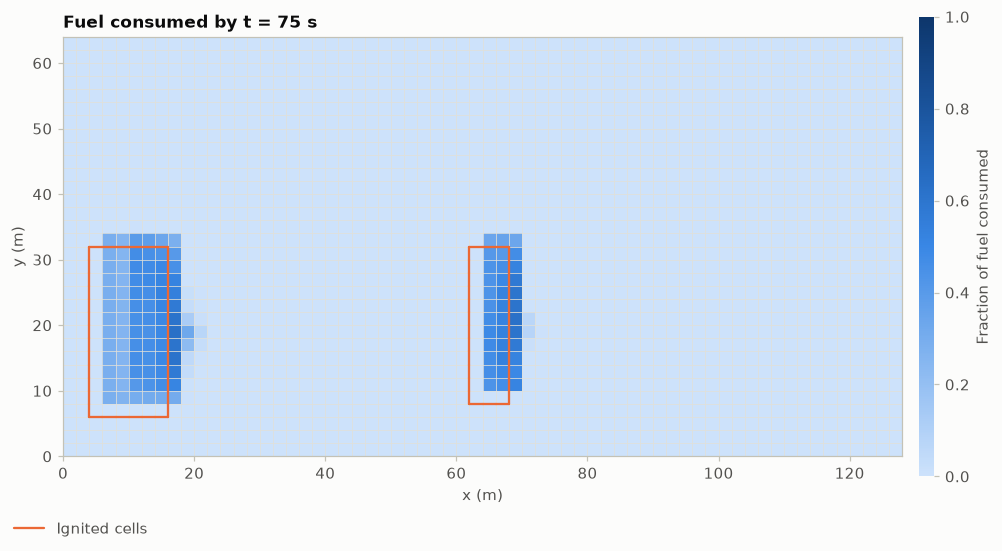

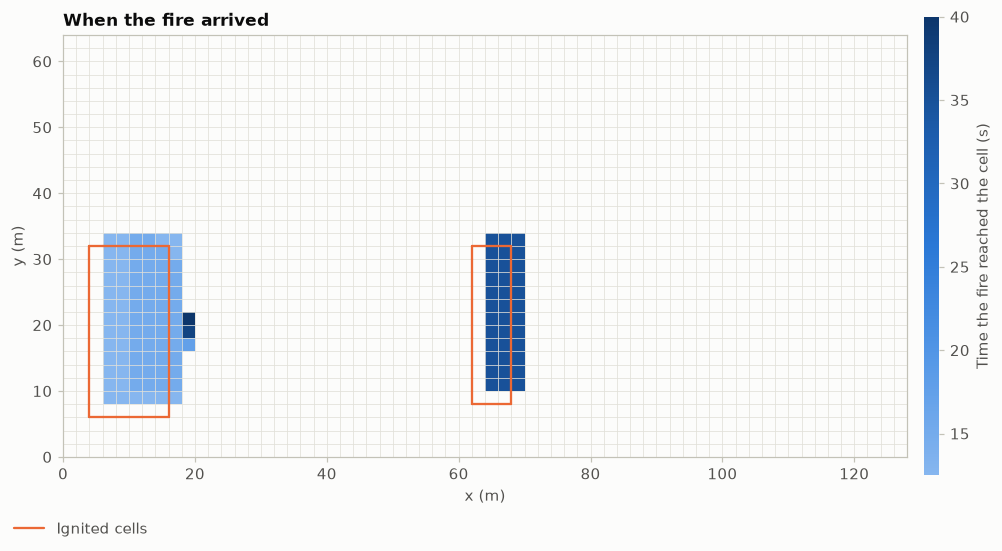

In [6]:
def plot_fuel_map(values, cmap, label, title, name, **limits):
    """A map of one ground quantity with the ignited cells outlined."""
    fig, ax = plt.subplots(figsize=map_figsize(ds), layout="constrained")
    mesh = ax.pcolormesh(ds.x, ds.y, values, cmap=cmap, shading="nearest", **limits)
    add_map_grid(ax, ds)
    add_colorbar(fig, mesh, ax, label)
    handle = add_ignition_outline(ax, ds)
    if handle is not None:
        fig.legend(handles=[handle], loc="outside lower left")
    style_map(ax, title)
    finish(fig, name)


if not fire_burned:
    display(Markdown("No fuel burned in this run, so there are no fuel maps."))
else:
    plot_fuel_map(consumed.isel(time=-1), AMOUNT_CMAP, "Fraction of fuel consumed",
                  f"Fuel consumed by t = {times[-1]:g} s", "fuel_consumed", vmin=0, vmax=1)
    plot_fuel_map(arrival_time, ORDER_CMAP, "Time the fire reached the cell (s)",
                  "When the fire arrived", "fire_arrival",
                  vmin=float(arrival_time.min()), vmax=float(arrival_time.max()))

## Fire progress over time

Heating is the rise in potential temperature above the ambient profile: FIRETEC's
start-up profile when the store has one (convert with the run's `run.log`), else
the median of each level at the first output. The plume top is the highest cell
whose air is at least `PLUME_THETA_RISE` warmer than ambient. Fields are read one
output at a time, so this works for large runs too.

In [7]:
def ambient_theta(ds):
    """Ambient potential temperature at each level (K)."""
    if "initial_potential_temperature" in ds:
        return ds.initial_potential_temperature.load()
    return ds.theta.isel(time=0).load().median(["y", "x"])


def height_above_ground(ds):
    """Height of each cell centre above the ground below it (m)."""
    if "terrain_height" not in ds:
        return ds.z
    top = ds.z.attrs["domain_top"]
    return ds.z * (top - ds.terrain_height) / top


def heating_and_plume_top(ds, ambient, plume_rise):
    """Peak heating at the lowest level and plume-top height, for each output."""
    heights = height_above_ground(ds)
    peak, top = [], []
    for index in range(ds.sizes["time"]):
        rise = ds.theta.isel(time=index).load() - ambient
        peak.append(float(rise.isel(z=0).max()))
        top.append(float(heights.where(rise >= plume_rise).max()))
    return np.array(peak), np.array(top)


ambient = ambient_theta(ds)
peak_heating, plume_top = heating_and_plume_top(ds, ambient, PLUME_THETA_RISE)

# Each panel: (title, unit, values, which point to label: "end" or "peak").
panels = []
if fire_burned:
    panels += [("Burned area", "m²", burned_area.values, "end"),
               ("Fuel consumed", "kg", fuel_consumed.values, "end")]
panels += [("Peak heating at the lowest level", "K", peak_heating, "peak"),
           ("Plume top", "m", plume_top, "peak")]
for title, *_ in [panel for panel in panels if not np.isfinite(panel[2]).any()]:
    display(Markdown(f"No {title.lower()} to plot: no air was {PLUME_THETA_RISE:g} K "
                     "warmer than ambient."))
panels = [panel for panel in panels if np.isfinite(panel[2]).any()]
progress = pd.DataFrame({f"{title} ({unit})": values for title, unit, values, _ in panels},
                        index=pd.Index(times, name="Time (s)"))

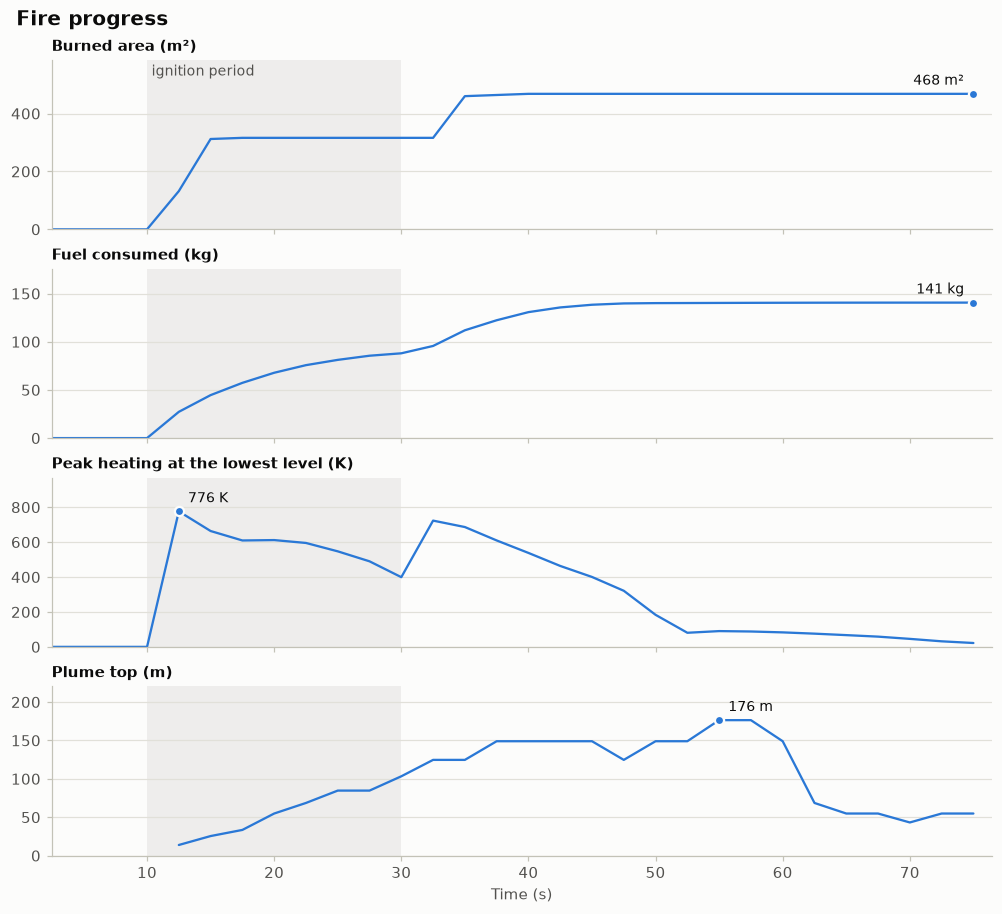

,Burned area (m²),Fuel consumed (kg),Peak heating at the lowest level (K),Plume top (m)
Time (s),,,,
2.5,0.0,0.00,0.00,NaN
5.0,0.0,0.00,0.00,NaN
7.5,0.0,0.00,0.00,NaN
10.0,0.0,0.00,0.00,NaN
12.5,132.0,27.24,775.95,13.87
15.0,312.0,44.60,663.51,25.49
17.5,316.0,57.34,609.36,33.48
20.0,316.0,67.80,611.59,54.82
22.5,316.0,75.70,595.12,68.58


In [8]:
def mark_ignition(axes, ds):
    """Shade the ignition period (or rule the ignition time) on every panel."""
    if "ignition_time" not in ds:
        return
    first, last = float(ds.ignition_time.min()), float(ds.ignition_time.max())
    for ax in axes:
        if last > first:
            ax.axvspan(first, last, color=COLORS["muted"], alpha=0.12, linewidth=0)
        else:
            ax.axvline(first, color=COLORS["muted"], linewidth=0.8)
    label = "ignition" if last == first else "ignition period"
    axes[0].annotate(label, xy=(first, 1), xycoords=("data", "axes fraction"),
                     xytext=(3, -3), textcoords="offset points", va="top",
                     color=COLORS["ink_secondary"], fontsize=9)


def format_value(value, unit):
    return f"{value:,.0f} {unit}" if abs(value) >= 10 else f"{value:.2g} {unit}"


def label_point(ax, time, value, unit, at_end):
    """Mark one point with a ringed dot and its value, kept inside the axes."""
    ax.plot(time, value, "o", markersize=6, color=COLORS["series"], zorder=3,
            markeredgecolor=COLORS["surface"], markeredgewidth=1.5)
    ax.annotate(format_value(value, unit), (time, value), xytext=(-6 if at_end else 6, 6),
                textcoords="offset points", ha="right" if at_end else "left",
                color=COLORS["ink"], fontsize=9)


def plot_progress(panels, times, ds):
    """One small panel per quantity on a shared time axis, each labelling its
    final value (running totals) or its peak."""
    fig, axes = plt.subplots(len(panels), 1, sharex=True, layout="constrained",
                             figsize=(9, 1.9 * len(panels) + 0.6))
    axes = np.atleast_1d(axes)
    for ax, (title, unit, values, label_at) in zip(axes, panels):
        ax.plot(times, values, color=COLORS["series"])
        ax.set_title(f"{title} ({unit})", fontsize=10)
        ax.grid(axis="y")
        ax.spines[["top", "right"]].set_visible(False)
        finite = np.flatnonzero(np.isfinite(values))
        if finite.size:
            index = finite[-1] if label_at == "end" else int(np.nanargmax(values))
            label_point(ax, times[index], values[index], unit, label_at == "end")
            ax.set_ylim(min(0.0, np.nanmin(values)), 1.25 * max(np.nanmax(values), 1e-9))
    mark_ignition(axes, ds)
    axes[-1].set_xlabel("Time (s)")
    span = max(times[-1] - times[0], 1e-9)
    axes[-1].set_xlim(times[0], times[-1] + 0.02 * span)   # room for the end dots
    fig.suptitle("Fire progress", x=0.01, ha="left")
    finish(fig, "fire_progress")


plot_progress(panels, times, ds)
display(progress.round(2))

## Heat and wind near the ground

Heating at the lowest grid level, with the wind there as streamlines (wider where
faster), at moments spread over the time the fire is burning (fuel is being
consumed; for runs without fire, while the ground air is heated by at least
`PLUME_THETA_RISE`). All maps share one color scale and one width scale.

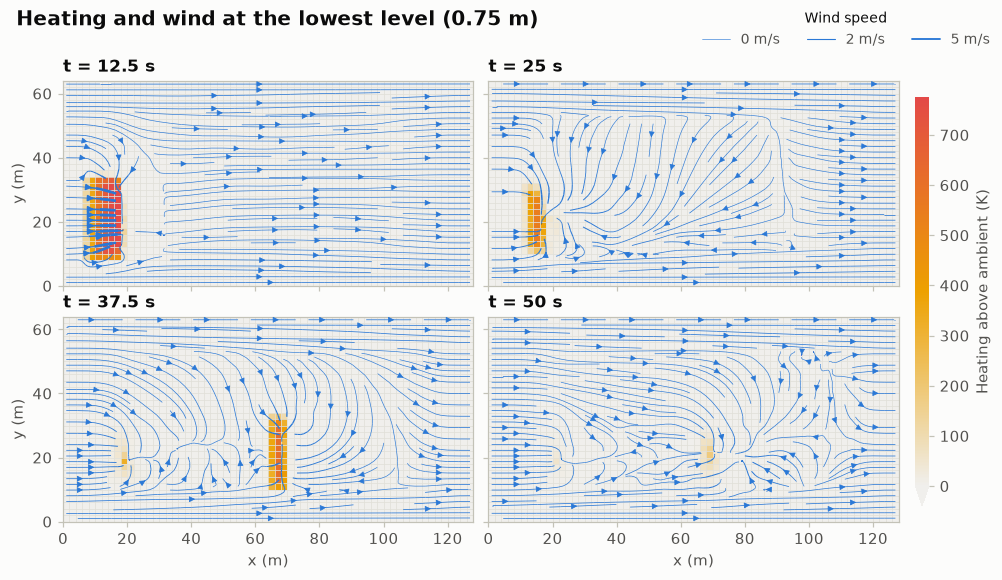

In [9]:
def active_period(fuel_consumed, peak_heating, threshold):
    """Indices of the first and last output while fuel burns at more than 1% of
    its peak rate (else, or without fuel data, while the ground air is heated)."""
    if fuel_consumed is not None:
        rate = np.diff(fuel_consumed, prepend=fuel_consumed[0])
        burning = np.flatnonzero(rate > 0.01 * rate.max()) if rate.max() > 0 else []
        if len(burning):
            return burning[0], burning[-1]
    heated = np.flatnonzero(peak_heating >= threshold)
    return (heated[0], heated[-1]) if heated.size else (0, len(peak_heating) - 1)


def snapshot_indices(first, last, count):
    return np.unique(np.linspace(first, last, count).round().astype(int))


def plot_ground_snapshots(ds, ambient, indices):
    frames = [ds.isel(time=index, z=0)[["theta", "u", "v"]].load() for index in indices]
    rises = [frame.theta - ambient.isel(z=0) for frame in frames]
    hottest = max(1.0, max(float(rise.max()) for rise in rises))
    fastest = max(float(np.hypot(frame.u, frame.v).max()) for frame in frames)

    columns = 2 if len(indices) > 1 else 1
    rows = int(np.ceil(len(indices) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=map_figsize(ds, columns, rows),
                             layout="constrained", sharex=True, sharey=True, squeeze=False)
    for ax, index, frame, rise in zip(axes.flat, indices, frames, rises):
        mesh = ax.pcolormesh(ds.x, ds.y, rise, cmap=HEAT_CMAP, vmin=0, vmax=hottest,
                             shading="nearest")
        add_map_grid(ax, ds)
        wind_streamlines(ax, ds, frame.u.values, frame.v.values, fastest)
        style_map(ax, f"t = {times[index]:g} s")
        ax.label_outer()
    for ax in axes.flat[len(indices):]:
        ax.set_visible(False)
    streamline_legend(fig, fastest)
    add_colorbar(fig, mesh, axes, "Heating above ambient (K)", extend="min")
    fig.suptitle(f"Heating and wind at the lowest level ({float(ds.z[0]):.2g} m)",
                 x=0.01, ha="left")
    finish(fig, "ground_heating_and_wind")


first, last = active_period(fuel_consumed.values if fire_burned else None, peak_heating,
                            PLUME_THETA_RISE)
plot_ground_snapshots(ds, ambient, snapshot_indices(first, last, SNAPSHOT_COUNT))

## Plume cross-section

A vertical slice along x at the output where the plume reaches highest, through
the row (y) that holds the most heat. Colors show heating above ambient; arrows
show the wind in the plane of the slice (its x and vertical components). Height
is drawn on a different scale from distance.

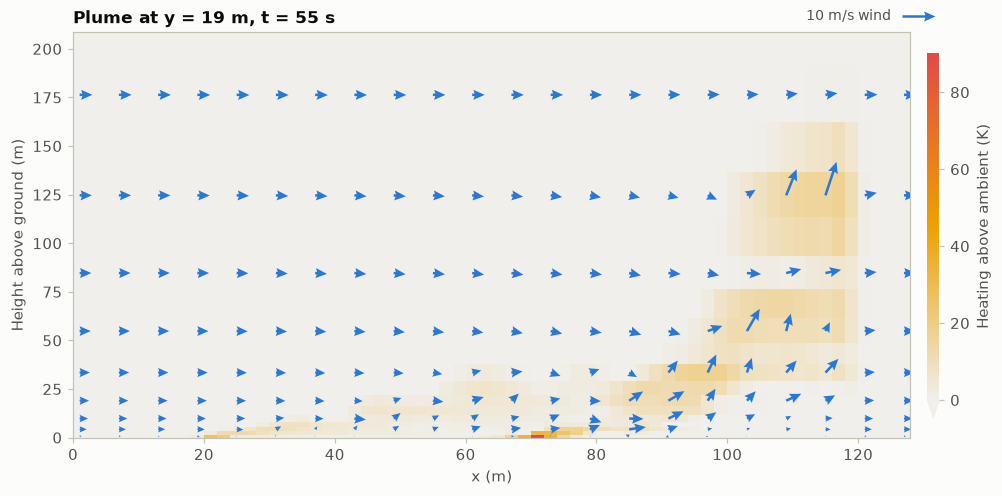

In [10]:
def plume_output(plume_top):
    """The output where the plume is tallest, or None if there is no plume."""
    return int(np.nanargmax(plume_top)) if np.isfinite(plume_top).any() else None


def hottest_row(rise):
    """The y row that holds the most heating."""
    return int(rise.clip(min=0).sum(["z", "x"]).argmax("y"))


def slice_top(ds, plume_height):
    """Top of a vertical slice: 40% above the plume, at least 20 m, at most the domain top."""
    return min(float(ds.z_bounds[-1, 1]), max(20.0, 1.4 * plume_height))


def row_heights(ds, row):
    """(z, x) heights above ground of the cell centres along one y row."""
    heights = height_above_ground(ds)
    heights = heights.isel(y=row) if "y" in heights.dims else heights.broadcast_like(ds.x)
    return heights.transpose("z", "x").values


def plot_plume_section(ds, ambient, index):
    rise = ds.theta.isel(time=index).load() - ambient
    j = hottest_row(rise)
    section = rise.isel(y=j).transpose("z", "x").values
    wind = ds.isel(time=index, y=j)[["u", "w"]].load().transpose("z", "x")
    heights = row_heights(ds, j)
    distance = np.broadcast_to(ds.x.values, heights.shape)

    in_plume = section >= PLUME_THETA_RISE
    ceiling = slice_top(ds, heights[in_plume].max() if in_plume.any() else 0.0)
    levels = np.flatnonzero(heights.min(axis=1) <= ceiling)
    x_step = max(1, round(ds.sizes["x"] / 24))
    picked = np.ix_(levels[::max(1, round(levels.size / 12))],
                    np.arange(0, ds.sizes["x"], x_step))
    fastest = float(np.hypot(wind.u, wind.w).values[picked].max())

    fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
    mesh = ax.pcolormesh(*section_corners(ds, j), section, cmap=HEAT_CMAP, shading="flat",
                         vmin=0, vmax=max(1.0, float(section.max())))
    add_colorbar(fig, mesh, ax, "Heating above ambient (K)", extend="min")
    ax.set_ylim(0, ceiling)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("Height above ground (m)")
    ax.set_title(f"Plume at y = {float(ds.y[j]):g} m, t = {times[index]:g} s")
    fig.canvas.draw()   # settle the layout, then size arrows to their spacing on screen
    spacing = ax.get_window_extent().width / fig.dpi * x_step / ds.sizes["x"]
    arrows = wind_arrows(ax, distance[picked], heights[picked], wind.u.values[picked],
                         wind.w.values[picked], longest=0.9 * spacing, max_speed=fastest,
                         units="inches")
    add_arrow_key(arrows, fastest)
    finish(fig, "plume_section")


tallest = plume_output(plume_top)
if tallest is None:
    display(Markdown(f"No plume: no air was {PLUME_THETA_RISE:g} K warmer than ambient."))
else:
    plot_plume_section(ds, ambient, tallest)

## The fire from start to finish

Every output (at most `MAX_ANIMATION_FRAMES`, spread over the run) as an
animation: press play, or drag the slider to any moment; the |◀ button returns to
the beginning. The top map shows heating at the lowest level, with the burned area
outlined in blue as it grows (cells that have lost `BURNED_FRACTION` of their fuel)
and the ignited cells in orange. Below, a vertical slice along x follows the row
marked on the map: the row holding the most heat when the plume is tallest. Both
panels share one logarithmic color scale, from `PLUME_THETA_RISE` (the plume's
edge) to the hottest flames, so the faint plume shows next to the fire.

The controls run in the cell's output. If you open a saved notebook and they do
not respond, run the cell again (or trust the notebook).

In [11]:
def animation_frames(count, limit):
    """Output indices to animate: all of them, or `limit` spread over the run."""
    return np.unique(np.linspace(0, count - 1, min(count, limit)).round().astype(int))


def fire_animation(ds, ambient, row, frames, *, burned, hottest, ceiling):
    """An HTML animation (with a slider) of heating near the ground and along one
    row, colored on a log scale from PLUME_THETA_RISE to `hottest`."""
    x_edges, y_edges = cell_edges(ds.x.values), cell_edges(ds.y.values)
    norm = LogNorm(PLUME_THETA_RISE, hottest)

    def heating(index):   # log scale: anything cooler than the plume edge is its floor
        return (ds.theta.isel(time=index).load() - ambient).clip(min=PLUME_THETA_RISE)

    map_height = (9.0 - 1.4) * np.ptp(y_edges) / np.ptp(x_edges)
    fig, (ground_ax, slice_ax) = plt.subplots(
        2, 1, figsize=(9, map_height + 3.8), height_ratios=[map_height, 2.4],
        layout="constrained")
    rise = heating(frames[0])
    ground = ground_ax.pcolormesh(ds.x, ds.y, rise.isel(z=0), cmap=HEAT_CMAP, norm=norm,
                                  shading="nearest")
    section = slice_ax.pcolormesh(*section_corners(ds, row), rise.isel(y=row).transpose("z", "x"),
                                  cmap=HEAT_CMAP, norm=norm, shading="flat")
    add_map_grid(ground_ax, ds)
    scar = LineCollection([], colors=COLORS["series"], linewidths=1.5, zorder=3)
    ground_ax.add_collection(scar)
    ground_ax.axhline(float(ds.y[row]), color=COLORS["ink_secondary"], linewidth=0.8, zorder=3)

    handles = [Line2D([], [], color=COLORS["ink_secondary"], linewidth=0.8,
                      label="Row shown in the slice")]
    if burned is not None:
        handles.insert(0, Line2D([], [], color=COLORS["series"], linewidth=1.5,
                                 label="Burned area"))
    ignition = add_ignition_outline(ground_ax, ds)
    if ignition is not None:
        handles.insert(1, ignition)
    fig.legend(handles=handles, loc="outside lower center", ncols=len(handles))
    bar = add_colorbar(fig, ground, [ground_ax, slice_ax], "Heating above ambient (K)",
                       extend="min")
    bar.locator = mpl.ticker.LogLocator(subs=(1, 3))
    bar.minorlocator = mpl.ticker.NullLocator()
    bar.formatter = mpl.ticker.StrMethodFormatter("{x:g}")
    style_map(ground_ax, f"Lowest level ({float(ds.z[0]):.2g} m)")
    slice_ax.set_ylim(0, ceiling)
    slice_ax.set_xlabel("x (m)")
    slice_ax.set_ylabel("Height above ground (m)")
    slice_ax.set_title(f"Slice at y = {float(ds.y[row]):g} m")
    title = fig.suptitle("", x=0.01, ha="left")

    def draw(index):
        rise = heating(index)
        ground.set_array(rise.isel(z=0).values)
        section.set_array(rise.isel(y=row).transpose("z", "x").values)
        if burned is not None:
            scar.set_segments(outline_segments(burned.isel(time=index).values,
                                               x_edges, y_edges))
        title.set_text(f"The fire at t = {float(ds.time[index]):g} s "
                       f"(step {int(ds.step[index])})")
        return ground, section, scar, title

    animation = FuncAnimation(fig, draw, frames=frames, interval=400)
    with mpl.rc_context({"savefig.dpi": 80, "animation.embed_limit": 200}):
        html = animation.to_jshtml(default_mode="once")
    plt.close(fig)
    return html


moment = tallest if tallest is not None else int(np.nanargmax(peak_heating))
row = hottest_row(ds.theta.isel(time=moment).load() - ambient)
frames = animation_frames(ds.sizes["time"], MAX_ANIMATION_FRAMES)
if len(frames) < ds.sizes["time"]:
    display(Markdown(f"Showing {len(frames)} of the {ds.sizes['time']} outputs."))
plume = float(np.nanmax(plume_top)) if np.isfinite(plume_top).any() else 0.0
animation_html = fire_animation(
    ds, ambient, row, frames, burned=burned if fire_burned else None,
    hottest=max(10 * PLUME_THETA_RISE, float(np.nanmax(peak_heating))),
    ceiling=slice_top(ds, plume))
if SAVE_FIGURES_TO:
    Path(SAVE_FIGURES_TO).mkdir(parents=True, exist_ok=True)
    (Path(SAVE_FIGURES_TO) / "fire_animation.html").write_text(animation_html)
display(HTML(animation_html))

## Start-up profile

The ambient profile FIRETEC printed at start-up, stored when the run's `run.log`
was available to the converter.

In [12]:
profile_names = {"initial_potential_temperature": ("Potential temperature (K)", 1.0),
                 "initial_density": ("Air density (kg/m³)", 1.0),
                 "initial_pressure": ("Pressure (hPa)", 0.01)}
if not all(name in ds for name in profile_names):
    display(Markdown("This store has no start-up profile: convert the run with its "
                     "`run.log` present (or pass `--log`) to include it."))
else:
    fig, axes = plt.subplots(1, 3, figsize=(9, 4), sharey=True, layout="constrained")
    for ax, (name, (label, scale)) in zip(axes, profile_names.items()):
        ax.plot(ds[name] * scale, ds.z, color=COLORS["series"])
        ax.ticklabel_format(axis="x", useOffset=False, style="plain")
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
        ax.set_title(label, fontsize=10)
        ax.grid(axis="x")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Height (m)")
    fig.suptitle("Start-up ambient profile", x=0.01, ha="left")
    finish(fig, "startup_profile")

This store has no start-up profile: convert the run with its `run.log` present (or pass `--log`) to include it.

## Explore further

Everything is in `ds`, an xarray Dataset. For example
`ds.theta.sel(time=30, method="nearest").isel(z=0).plot()` maps the lowest-level
potential temperature at 30 s, and `ds.attrs["firetec_parameters"]` lists every
run parameter with its description.

In [13]:
ds

<xarray.Dataset> Size: 40MB
Dimensions:                      (ignition_point: 114, time: 30, z: 20, y: 32,
                                  x: 64, fuel_type: 1, z_fuel: 1, bnds: 2)
Coordinates:
  * time                         (time) float64 240B 2.5 5.0 7.5 ... 72.5 75.0
    step                         (time) int64 240B ...
  * z                            (z) float64 160B 0.7542 2.364 ... 241.4 279.5
    sigma                        (z) float64 160B 7.5 22.5 37.5 ... 277.5 292.5
  * y                            (y) float64 256B 1.0 3.0 5.0 ... 59.0 61.0 63.0
  * x                            (x) float64 512B 1.0 3.0 5.0 ... 125.0 127.0
  * fuel_type                    (fuel_type) int32 4B 1
  * z_fuel                       (z_fuel) float64 8B 0.7542
Dimensions without coordinates: ignition_point, bnds
Data variables: (12/21)
    ignition_i                   (ignition_point) int32 456B 3 3 3 ... 34 34 34
    ignition_j                   (ignition_point) int32 456B 4 5 6 ... 14 15 16
    ignition_k                   (ignition_point) int32 456B ...
    ignition_ramp_rate           float64 8B ...
    ignition_target_temperature  float64 8B ...
    ignition_time                (ignition_point) float64 912B 10.0 ... 30.0
    ...                           ...
    sies                         (time, fuel_type, z_fuel, y, x) float32 246kB ...
    theta                        (time, z, y, x) float32 5MB ...
    u                            (time, z, y, x) float32 5MB ...
    v                            (time, z, y, x) float32 5MB ...
    w                            (time, z, y, x) float32 5MB ...
    z_bounds                     (z, bnds) float64 320B 0.0 1.534 ... 300.0
Attributes: (12/21)
    title:                               FIRETEC 1.5.0 simulation TestRun-64x...
    summary:                             Atmosphere and fuel fields of a FIRE...
    source:                              FIRETEC 1.5.0 (Los Alamos National L...
    Conventions:                         CF-1.10
    date_created:                        2026-11-09T18:30:12+00:00
    history:                             2026-11-09T18:30:12+00:00: firetec_t...
    ...                                  ...
    firetec_missing_output_steps:        []
    firetec_gridlist:                    nt = 7500\nfrqoutput = 250\nnprocx =...
    input_files:                         [{'path': 'gridlist', 'bytes': 97, '...
    output_files:                        [{'path': 'comp/comp.out.250', 'byte...
    firetec_repository:                  {'url': 'https://github.com/national...
    software:                            {'converter': 'firetec_to_zarr.py 1....